# M3 step by step, with whisper-tiny

M3 (Ahmadi & Sennrich 2026) fine-tunes a Whisper encoder to locate a speaker on a grid over
Switzerland, then throws the classification head away and predicts with cell prototypes:

1. **Classes**: the centroid cells of the training municipalities; every unit (clip or segment) is
   labelled with the cell of its speaker's municipality.
2. **Training**: a linear head on the encoder output, mean-pooled over the frames with audio,
   trained with cross-entropy (AdamW, linear warmup and decay).
3. **Inference**: re-embed train, valid and test with the fine-tuned encoder, build one prototype per
   cell in each mapping mode (centroid / uniform / gaussian) and give every unit its most
   cosine-similar prototype. This is B2 on fine-tuned embeddings.

`uv run train` does all of this (`src/maloney/train.py`). This notebook takes the same steps with
the same library code, but on a small sample of the local `smoke` split and only a few
optimizer steps, so it runs on a laptop in a few minutes. The numbers only show the mechanics,
not how well M3 works.

In [1]:
import tempfile
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import get_linear_schedule_with_warmup

from maloney.baselines.evaluate import GeoContext, evaluate
from maloney.baselines.methods import NearestPrototype
from maloney.baselines.run import evaluate_method
from maloney.baselines.units import unit_table
from maloney.data.stt4sg import STT4SGDataModule, STT4SGDataset
from maloney.embeddings.whisper import pool_frames
from maloney.geo import MODES, CellMapping, Geolects, Grid, Municipalities
from maloney.models.whisper_geo import WhisperCollate, WhisperGeoClassifier, class_index
from maloney.train import HeadMethod, target_classes

DATA_DIR = Path("../data/stt4sg-350_v2-1")
GEO_DIR = Path("../data/geo")
SPLIT_DIR = DATA_DIR / "splits" / "smoke"  # speaker-disjoint split of test.tsv

MODEL = "openai/whisper-tiny"  # 4 encoder layers, d_model 384
POOL_LAYER = 4                 # layer that is pooled (layers above it are dropped)
FREEZE_LAYERS = 0              # lowest transformer layers kept fixed (the conv front end always is)
CELL_SIZE = 10_000              # metres, as configs/geo/default.yaml
SIGMA, NEIGHBOUR_DISTANCE = 20_000, 4_000

CLIPS_PER_MUNI = 40            # training sample: clips per municipality
CLIPS_PER_SPEAKER = 15         # valid/test sample: clips per speaker
STEPS, BATCH_SIZE, LR, WARMUP = 500, 16, 1e-4, 0.1
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
torch.manual_seed(0)
print(DEVICE)

/Users/felix/PhD/02_Edu/maloney/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1027 10:19:13.472000 53117 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


mps


## 1. Data

The data module reads the split, attaches every speaker's municipality and centroid (LV95, metres)
and serves waveforms from `audio_16k.h5`. Items here are single clips (`segment_duration=None`). The
full runs use `data.segment_duration=20`, which joins ~20 s of one speaker into one item. To keep this
quick, each split is cut down to a sample of its clips.

In [2]:
dm = STT4SGDataModule(DATA_DIR, DATA_DIR / "audio_16k.h5", split_dir=SPLIT_DIR,
                      geo_table=DATA_DIR / "zip_municipality.csv", segment_duration=None, num_workers=0)
dm.setup()


def subsample(split: str, by: str, n: int):
    ds = dm.datasets[split]
    meta = ds.meta.sample(frac=1, random_state=0)
    meta = meta[meta.groupby(by).cumcount() < n].sort_index()
    dm.datasets[split] = STT4SGDataset(meta, ds.audio_h5, ds.vocabs, ds.sample_rate, ds.h5_sample_rate, ds.segment_gap)


subsample("train", "bfs_nr", CLIPS_PER_MUNI)
for split in ("valid", "test"):
    subsample(split, "client_id", CLIPS_PER_SPEAKER)
pd.DataFrame({split: {"clips": len(ds), "speakers": ds.meta.client_id.nunique(),
                      "municipalities": ds.meta.bfs_nr.nunique(), "hours": ds.durations.sum() / 3600}
              for split, ds in dm.datasets.items()}).T.round(2)

,clips,speakers,municipalities,hours
train,1600.0,47.0,40.0,2.23
valid,210.0,14.0,14.0,0.29
test,210.0,14.0,14.0,0.30


## 2. Classes: centroid cells of the training municipalities

The grid keeps the 5 km cells that overlap Switzerland. Each training municipality (a *geolect*)
puts its clips into the cell of its centroid, and the set of these cells is the classes. The split
is speaker-disjoint, so most valid and test speakers live in municipalities that have no class of
their own. This is why the head is not the final predictor: prototypes in the uniform and gaussian
modes also cover cells around the training municipalities.

Grid(505 active cells of 10 km, 36x23 from LV95 (2480000, 1070000))
40 training municipalities -> 35 classes; 5/14 valid municipalities fall into a class cell


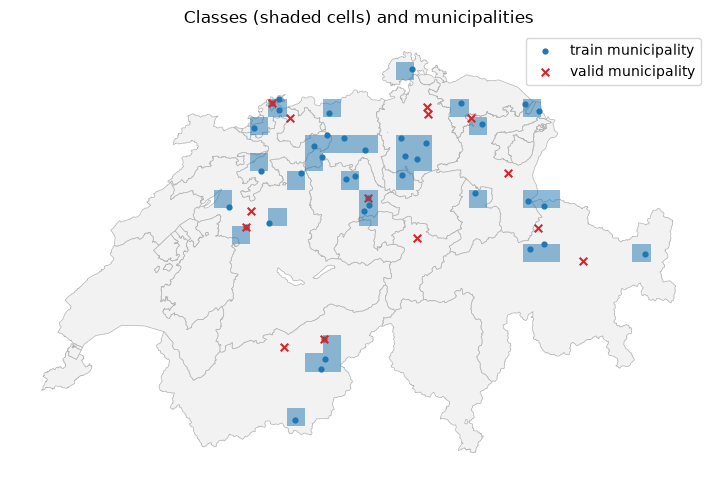

In [3]:
grid = Grid.from_file(GEO_DIR / "cantons.geojson", CELL_SIZE)
geolects = Geolects.from_meta(dm.datasets["train"].meta)
classes = np.unique(grid.cell_of(geolects.xy))
munis = Municipalities(GEO_DIR / "municipalities.geojson")
mappings = {mode: CellMapping(mode, sigma=SIGMA, neighbour_distance=NEIGHBOUR_DISTANCE, municipalities=munis)
            for mode in MODES}
geos = {mode: GeoContext(grid, mapping, geolects) for mode, mapping in mappings.items()}

valid_geolects = Geolects.from_meta(dm.datasets["valid"].meta)
known = class_index(grid.cell_of(valid_geolects.xy), classes) >= 0
print(f"{grid}\n{len(geolects)} training municipalities -> {len(classes)} classes; "
      f"{known.sum()}/{len(known)} valid municipalities fall into a class cell")

fig, ax = plt.subplots(figsize=(9, 6))
gpd.GeoSeries(list(grid.regions.values()), crs=2056).plot(ax=ax, color="0.95", edgecolor="0.7", lw=0.5)
gpd.GeoSeries(grid.boxes[classes], crs=2056).plot(ax=ax, color="tab:blue", alpha=0.5)
ax.scatter(*geolects.xy.T, s=12, c="tab:blue", label="train municipality")
ax.scatter(*valid_geolects.xy.T, s=30, marker="x", c="tab:red", label="valid municipality")
ax.set_title("Classes (shaded cells) and municipalities"); ax.legend(); ax.set_axis_off()

## 3. From waveforms to encoder input

`WhisperCollate` adds Whisper's log-mel features to every batch. Whisper only takes 30 s inputs
(3000 mel frames, the rest is padding), and its encoder halves the frame rate to 1500 output frames.
`frames` counts the output frames that hold audio, and only those are pooled. A clip longer than 30 s
would be cut into chunks, and `owner` says which item each chunk belongs to.

audio_lengths   (16,)
n_clips         ()
dialect         (16,)
canton          (16,)
zipcode         list[16]
client_id       list[16]
path            list[16]
bfs_nr          (16,)
municipality    list[16]
lv95            (16, 2)
latlon          (16, 2)
input_features  (16, 80, 3000)
frames          (16,)
owner           (16,)


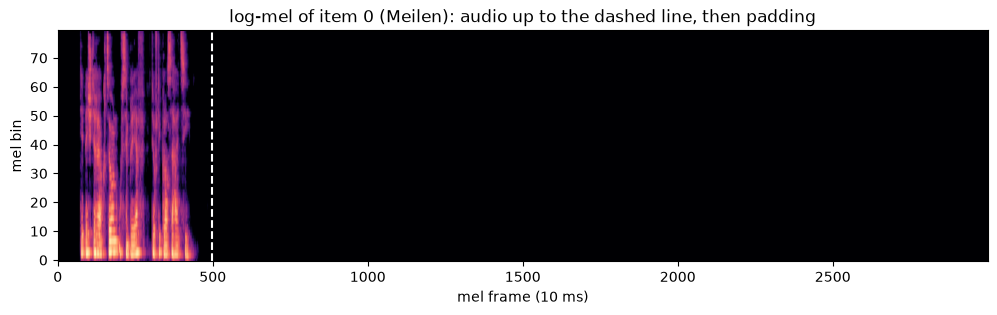

In [4]:
collate = WhisperCollate(MODEL)
batch = next(iter(dm.dataloader("train", collate_fn=collate, batch_size=BATCH_SIZE)))
for key, value in batch.items():
    print(f"{key:15s}", tuple(value.shape) if torch.is_tensor(value) else f"list[{len(value)}]")

i = 0
fig, ax = plt.subplots(figsize=(12, 3))
ax.imshow(batch["input_features"][i], origin="lower", aspect="auto", cmap="magma")
ax.axvline(2 * batch["frames"][i], color="w", ls="--")
ax.set(title=f"log-mel of item {i} ({batch['municipality'][i]}): audio up to the dashed line, then padding",
       xlabel="mel frame (10 ms)", ylabel="mel bin");

## 4. The model

`WhisperGeoClassifier` keeps the encoder up to `pool_layer` and adds a linear head with one output
per class. `embed` gives the pooled embedding, `forward` gives the logits. Pooling averages the hidden
states over the audio frames only, as in the precomputed embeddings for the baselines.

In [5]:
model = WhisperGeoClassifier(MODEL, len(classes), POOL_LAYER, FREEZE_LAYERS).to(DEVICE)
total, trainable = model.n_parameters()
print(f"{MODEL} pooled at layer {model.pool_layer}: {total / 1e6:.1f}M parameters, {trainable / 1e6:.1f}M trainable, "
      f"head {tuple(model.head.weight.shape)}")

with torch.no_grad():
    hidden = model.encoder(batch["input_features"].to(DEVICE)).last_hidden_state  # [chunks, 1500, 384]
    pooled = pool_frames(hidden, batch["frames"].to(DEVICE), batch["owner"].to(DEVICE), int(batch["n_clips"]))
    manual = hidden[i, : batch["frames"][i]].mean(0)
print("hidden", tuple(hidden.shape), "-> pooled", tuple(pooled.shape),
      "| item 0 equals the mean over its audio frames:", torch.allclose(pooled[i], manual, atol=1e-5))
print("targets (class index of each item's centroid cell):", target_classes(batch, grid, classes).tolist())

Loading weights: 100%|██████████| 167/167 [00:00<00:00, 7149.33it/s]


openai/whisper-tiny pooled at layer 4: 8.2M parameters, 7.7M trainable, head (35, 384)
hidden (16, 1500, 384) -> pooled (16, 384) | item 0 equals the mean over its audio frames: True
targets (class index of each item's centroid cell): [24, 23, 33, 9, 1, 21, 7, 24, 28, 10, 5, 5, 29, 0, 5, 31]


## 5. Before fine-tuning: prototypes from the pretrained encoder

For a reference point, here is step 3 on the untrained encoder (B2 on whisper-tiny). `embed_split`
runs the model over a split in loader order and returns the pooled embeddings, the head logits and the
unit table. `prototype_results` fits `NearestPrototype` in each mode on the train embeddings and
evaluates valid, per clip and per speaker (clip scores averaged), like `maloney.train.prototype_inference`.

In [6]:
OUT = Path(tempfile.mkdtemp())  # evaluate_method writes the prediction csvs here


@torch.no_grad()
def embed_split(split: str):
    model.eval()
    x, logits = [], []
    for b in dm.dataloader(split, shuffle=False, collate_fn=collate, batch_size=32):
        emb = model.embed(b)
        x.append(emb.cpu()); logits.append(model.head(emb).cpu())
    return torch.cat(x).numpy(), torch.cat(logits).numpy(), unit_table(dm, split, "clip", shuffle=False)[0]


def prototype_results(name: str, splits=("valid",)) -> tuple[pd.DataFrame, dict]:
    t = time.time()
    embedded = {split: embed_split(split) for split in ("train", *splits)}
    x_train, _, train_units = embedded["train"]
    rows = {}
    for mode, geo in geos.items():
        method = NearestPrototype()
        method.fit(x_train, train_units, geo)
        data = {split: (x, units) for split, (x, _, units) in embedded.items() if split != "train"}
        for key, metrics in evaluate_method(method, geo, data, "clip", OUT, tag=f"_{name}_{mode}").items():
            rows[(name, f"prototype_{mode}", key)] = metrics
    logits = {split: (lg, units) for split, (_, lg, units) in embedded.items() if split != "train"}
    for key, metrics in evaluate_method(HeadMethod(classes), geos["centroid"], logits, "clip", OUT, tag=f"_{name}_head").items():
        rows[(name, "head", key)] = metrics
    print(f"embedded {sum(len(e[0]) for e in embedded.values())} clips in {time.time() - t:.0f} s")
    return pd.DataFrame(rows).T, embedded


COLUMNS = ["n", "region_acc", "region_acc_majority", "cell_acc", "acc@0", "acc@1", "mean_km", "median_km"]
before, _ = prototype_results("pretrained")
before.loc[(slice(None), slice(None), "valid/speaker"), COLUMNS].round(3)

embedded 1810 clips in 35 s


n  region_acc  \
pretrained prototype_centroid valid/speaker  14.0       0.143   
           prototype_uniform  valid/speaker  14.0       0.286   
           prototype_gaussian valid/speaker  14.0       0.571   
           head               valid/speaker  14.0       0.143   

                                             region_acc_majority  cell_acc  \
pretrained prototype_centroid valid/speaker                0.143     0.000   
           prototype_uniform  valid/speaker                0.286     0.071   
           prototype_gaussian valid/speaker                0.214     0.357   
           head               valid/speaker                0.143     0.000   

                                             acc@0  acc@1  mean_km  median_km  
pretrained prototype_centroid valid/speaker    0.0  0.143   84.453    102.250  
           prototype_uniform  valid/speaker    0.0  0.071   71.864     66.782  
           prototype_gaussian valid/speaker    0.0  0.000   97.325     87.496  
           head               valid/speaker    0.0  0.000   79.964     81.623

## 6. Fine-tuning

This is the training loop of `maloney.train.train` without checkpoints, accumulation and mixed precision.
Each batch is labelled with the class of its municipality's centroid cell, and the loss is
cross-entropy over the head's logits. Parameters with at least 2 dimensions get weight decay. The
learning rate warms up linearly over `WARMUP` of the steps and then decays to 0. Gradients are
clipped at norm 1.

step 20/500: loss 3.590, 16.5 clips/s
step 40/500: loss 3.270, 17.1 clips/s
step 60/500: loss 2.770, 17.3 clips/s
step 80/500: loss 1.999, 17.4 clips/s
step 100/500: loss 1.247, 17.6 clips/s
step 120/500: loss 0.630, 17.7 clips/s
step 140/500: loss 0.484, 17.5 clips/s
step 160/500: loss 0.318, 17.5 clips/s
step 180/500: loss 0.223, 17.5 clips/s
step 200/500: loss 0.248, 17.6 clips/s
step 220/500: loss 0.104, 17.4 clips/s
step 240/500: loss 0.094, 17.2 clips/s
step 260/500: loss 0.058, 17.0 clips/s
step 280/500: loss 0.021, 17.0 clips/s
step 300/500: loss 0.026, 17.1 clips/s
step 320/500: loss 0.011, 17.2 clips/s
step 340/500: loss 0.010, 17.3 clips/s
step 360/500: loss 0.003, 17.4 clips/s
step 380/500: loss 0.005, 17.5 clips/s
step 400/500: loss 0.002, 17.5 clips/s
step 420/500: loss 0.001, 17.6 clips/s
step 440/500: loss 0.001, 17.6 clips/s
step 460/500: loss 0.001, 17.7 clips/s
step 480/500: loss 0.001, 17.7 clips/s
step 500/500: loss 0.001, 17.7 clips/s


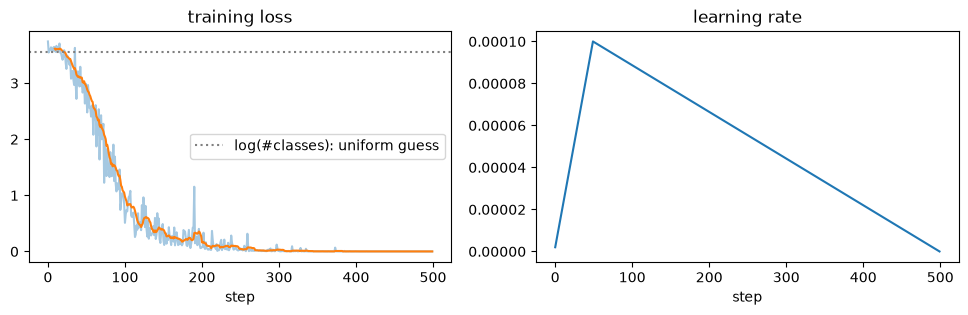

In [7]:
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW([{"params": [p for p in params if p.dim() >= 2], "weight_decay": 0.01},
                               {"params": [p for p in params if p.dim() < 2], "weight_decay": 0.0}], lr=LR)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP * STEPS), STEPS)
train_loader = dm.dataloader("train", collate_fn=collate, batch_size=BATCH_SIZE)

losses, lrs, step, t = [], [], 0, time.time()
model.train()
while step < STEPS:
    for batch in train_loader:
        targets = target_classes(batch, grid, classes).to(DEVICE)
        loss = torch.nn.functional.cross_entropy(model(batch), targets)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        optimizer.step()
        scheduler.step()
        losses.append(loss.item()); lrs.append(scheduler.get_last_lr()[0]); step += 1
        if step % 20 == 0:
            print(f"step {step}/{STEPS}: loss {np.mean(losses[-20:]):.3f}, {step * BATCH_SIZE / (time.time() - t):.1f} clips/s")
        if step == STEPS:
            break

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3))
a.plot(losses, alpha=0.4); a.plot(pd.Series(losses).rolling(10).mean())
a.axhline(np.log(len(classes)), color="0.5", ls=":", label="log(#classes): uniform guess"); a.legend()
a.set(title="training loss", xlabel="step"); b.plot(lrs); b.set(title="learning rate", xlabel="step");

## 7. Fine-tuned encoder: head vs. prototypes

After training, `train.py` loads the best checkpoint, which is selected on the valid head metrics (`monitor`,
default median km). Here the final weights are used. The head can only predict class cells. The
prototypes are rebuilt from the fine-tuned train embeddings and can also predict cells next to the
training municipalities in the uniform and gaussian modes.

In [8]:
after, embedded = prototype_results("fine-tuned")
results = pd.concat([before, after])
table = results.loc[(slice(None), slice(None), "valid/speaker"), COLUMNS].droplevel(2)
table.round(3)

embedded 1810 clips in 35 s


n  region_acc  region_acc_majority  \
pretrained prototype_centroid  14.0       0.143                0.143   
           prototype_uniform   14.0       0.286                0.286   
           prototype_gaussian  14.0       0.571                0.214   
           head                14.0       0.143                0.143   
fine-tuned prototype_centroid  14.0       0.286                0.286   
           prototype_uniform   14.0       0.286                0.286   
           prototype_gaussian  14.0       0.500                0.214   
           head                14.0       0.214                0.214   

                               cell_acc  acc@0  acc@1  mean_km  median_km  
pretrained prototype_centroid     0.000  0.000  0.143   84.453    102.250  
           prototype_uniform      0.071  0.000  0.071   71.864     66.782  
           prototype_gaussian     0.357  0.000  0.000   97.325     87.496  
           head                   0.000  0.000  0.000   79.964     81.623  
fine-tuned prototype_centroid     0.000  0.000  0.071   83.989     90.396  
           prototype_uniform      0.143  0.000  0.143   80.022     84.251  
           prototype_gaussian     0.357  0.071  0.143   87.320     86.101  
           head                   0.000  0.000  0.071   85.419     90.396

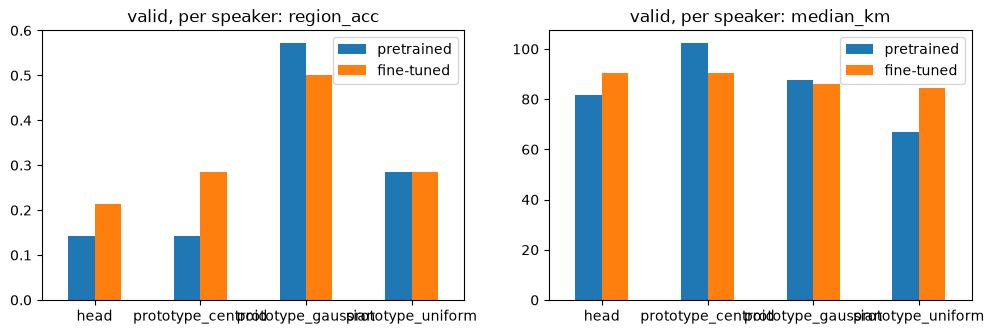

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, metric in zip(axes, ["region_acc", "median_km"]):
    table[metric].unstack(0)[["pretrained", "fine-tuned"]].plot.bar(ax=ax, rot=0)
    ax.set(title=f"valid, per speaker: {metric}", xlabel="")

### Where do the valid speakers end up?

Each speaker's prediction in gaussian mode, from their clip scores averaged. The line runs from the
true municipality to the midpoint of the predicted cell.

,municipality,dialect_region,pred_region,error_km
0,Bern,Bern,Wallis,87.4
1,Altdorf (UR),Innerschweiz,Graubünden,76.3
2,Untervaz,Graubünden,Graubünden,63.3
3,Liestal,Basel,Basel,16.9
4,Winterthur,Zürich,Zürich,64.0
5,Basel,Basel,Innerschweiz,110.4
6,Münchenbuchsee,Bern,Ostschweiz,154.8
7,Naters,Wallis,Graubünden,84.8
8,Seuzach,Zürich,Zürich,10.8
9,Wil (SG),Ostschweiz,Bern,202.0


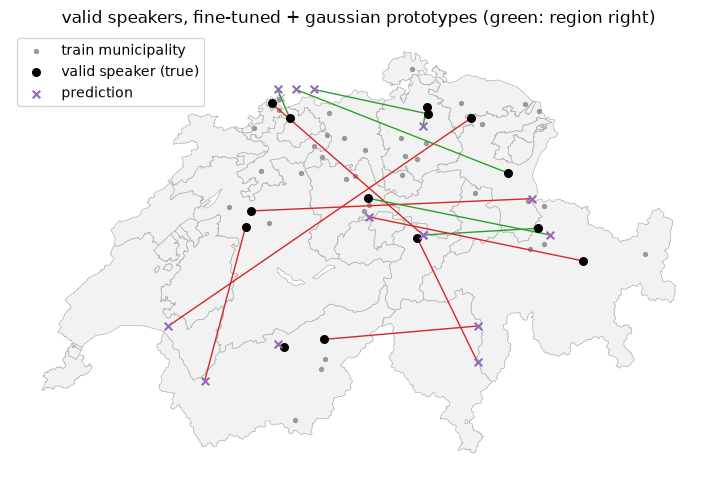

In [10]:
pred = pd.read_csv(OUT / "predictions_valid_speaker_fine-tuned_gaussian.csv")
fig, ax = plt.subplots(figsize=(9, 6))
gpd.GeoSeries(list(grid.regions.values()), crs=2056).plot(ax=ax, color="0.95", edgecolor="0.7", lw=0.5)
ax.scatter(*geolects.xy.T, s=8, c="0.6", label="train municipality")
for _, r in pred.iterrows():
    ax.plot([r.muni_E, r.pred_E], [r.muni_N, r.pred_N], color="tab:red" if r.pred_region != r.dialect_region else "tab:green", lw=1)
ax.scatter(pred.muni_E, pred.muni_N, s=30, c="k", label="valid speaker (true)", zorder=3)
ax.scatter(pred.pred_E, pred.pred_N, s=30, marker="x", c="tab:purple", label="prediction", zorder=3)
ax.set_title("valid speakers, fine-tuned + gaussian prototypes (green: region right)"); ax.legend(); ax.set_axis_off()
pred[["municipality", "dialect_region", "pred_region", "error_km"]].round(1)

## Going further

- More steps, the full data and segments instead of clips: `uv run train run_name=... model.name=openai/whisper-tiny
  data.segment_duration=20 trainer.device=mps` (see the README). `train.py` also handles checkpoints,
  resuming, mixed precision on CUDA and the final evaluation on test.
- Things to try here: `POOL_LAYER` (dialect information often peaks in the middle layers), `FREEZE_LAYERS`,
  `LR`, `STEPS`, and `center=True` for `NearestPrototype`, which subtracts the mean training embedding.